# 1. Modeling Human Activity States Using Hidden Markov Models

This project uses phone accelerometer data to recognise four activities: Standing, Walking, Jumping and Still.
I only have Total Acceleration (no gyroscope) because my phone does not have a gyroscope sensor.
I will cut my recordings into short files, extract features from the signals, build a Hidden Markov Model from scratch with numpy, and test it on recordings that the model has never seen.

This first part of the notebook is only about the data. It loads the long recordings, checks the real sampling rate, looks for bad parts, cuts everything into short labelled files, counts the data, and chooses a window size. The features and the model come after this part.

# 2. Imports

In [1]:
import re
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mode
from scipy.fft import fft, fftfreq

warnings.filterwarnings("ignore")

# 3. Settings

All the numbers I may want to change are in one cell, so I do not have to search for them later.

- `TEST_RECORDINGS` are the recordings I keep away from training. A name like `jumping2` means the file `Jumping2_TotalAcceleration.csv`, and the file without a number (`Jumping_TotalAcceleration.csv`) is `jumping1`. The model never sees them until the final test. I hold out whole recordings (not pieces of the same recording), because pieces that sit next to each other look almost the same and would make the test too easy.
- `TARGET_HZ` is the one sampling rate that every recording is converted to. My phone really gives about 27.5 Hz (I measure this below), so I convert to a clean 25 Hz. At 25 Hz a 5 second clip has exactly 125 samples.
- `CLIP_SECONDS` is the length of each short file.
- `TRIM_SECONDS` is cut from the start and the end of every recording, because my hand is still moving when I press the start and stop buttons.
- The three `TOO_...` and `MOVING_...` numbers are for the clip check in section 8.

In [2]:
KAGGLE_INPUT = Path("/kaggle/input/datasets/divineifechukwude/activity-dataset")
RAW_DIR = KAGGLE_INPUT if KAGGLE_INPUT.exists() else Path("raw_data")
OUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
DATASET_DIR = OUT_ROOT / "dataset"
FIG_DIR = OUT_ROOT / "figures"

ACTIVITIES = ["standing", "walking", "jumping", "still"]

TEST_RECORDINGS = ["jumping2", "standing2", "still2", "walking2"]

APP_SETTING_MS = 20
TARGET_HZ = 25

CLIP_SECONDS = 5
TRIM_SECONDS = 1

TOO_BUSY_FACTOR = 3.0
TOO_CALM_FACTOR = 0.4
MOVING_LEVEL = 0.5

WINDOW_SECONDS = 2.0
WINDOW_OVERLAP = 0.5

MIN_SECONDS_PER_ACTIVITY = 90
TARGET_FILES_PER_ACTIVITY = 50

FIG_DIR.mkdir(exist_ok=True, parents=True)
DATASET_DIR.mkdir(exist_ok=True, parents=True)
print("Reading files from:", RAW_DIR)

Reading files from: /kaggle/input/datasets/divineifechukwude/activity-dataset


# 4. Load the recordings

Each file is one long recording from Sensor Logger. The file name tells me the activity, for example `Walking2_TotalAcceleration.csv` is my second walking recording. I take the label from the file name, so I never have to guess a label from the data.

The columns are `time`, `seconds_elapsed`, `z`, `y` and `x`. I use `seconds_elapsed` as the time.

In [3]:
FILE_PATTERN = re.compile(r"([A-Za-z]+)(\d*)_TotalAcceleration\.csv$")

def rate_stats(t):
    dt = np.diff(t)
    return {
        "seconds": t[-1] - t[0],
        "real_hz": (len(t) - 1) / (t[-1] - t[0]),
        "mean_dt_ms": dt.mean() * 1000,
        "dt_std_ms": dt.std() * 1000,
        "max_gap_ms": dt.max() * 1000,
    }

recordings = []
for path in sorted(RAW_DIR.rglob("*_TotalAcceleration.csv")):
    match = FILE_PATTERN.search(path.name)
    if match is None:
        continue
    activity = match.group(1).lower()
    if activity not in ACTIVITIES:
        warnings.warn(f"Unknown activity in file name {path.name}, skipping it.")
        continue
    rec_id = f"{activity}{match.group(2) or '1'}"
    df = pd.read_csv(path)[["seconds_elapsed", "x", "y", "z"]].dropna()
    df = df.sort_values("seconds_elapsed").drop_duplicates("seconds_elapsed").reset_index(drop=True)
    recordings.append({
        "rec_id": rec_id,
        "activity": activity,
        "split": "test" if rec_id in TEST_RECORDINGS else "train",
        "file": path.name,
        "raw": df,
        "stats": rate_stats(df["seconds_elapsed"].values),
    })

if len(recordings) == 0:
    raise FileNotFoundError(f"No *_TotalAcceleration.csv files found in {RAW_DIR}")

recording_table = pd.DataFrame([{
    "recording": r["rec_id"],
    "split": r["split"],
    "rows": len(r["raw"]),
    "seconds": round(r["stats"]["seconds"], 1),
    "real_hz": round(r["stats"]["real_hz"], 2),
    "mean_dt_ms": round(r["stats"]["mean_dt_ms"], 2),
    "dt_std_ms": round(r["stats"]["dt_std_ms"], 2),
    "max_gap_ms": round(r["stats"]["max_gap_ms"], 1),
} for r in recordings]).sort_values(["recording"]).reset_index(drop=True)
recording_table

,recording,split,rows,seconds,real_hz,mean_dt_ms,dt_std_ms,max_gap_ms
0,jumping1,train,921,33.4,27.51,36.35,0.58,40.6
1,jumping2,test,1412,51.1,27.61,36.22,1.10,39.2
2,jumping3,train,1693,61.3,27.59,36.24,1.09,48.9
3,jumping4,train,1453,52.7,27.54,36.31,0.54,47.1
4,jumping5,train,2079,75.3,27.58,36.26,0.93,48.9
5,standing1,train,3861,140.3,27.51,36.35,0.07,40.2
6,standing2,test,3003,108.8,27.58,36.26,0.95,45.9
7,standing3,train,2301,83.4,27.57,36.27,0.83,51.8
8,still1,train,5157,187.4,27.51,36.35,0.50,51.3
9,still2,test,5722,207.7,27.55,36.30,0.51,49.0


### 4.1 What the loading result shows

All twelve recordings loaded without errors, and none of them has missing values. I have five jumping recordings (33, 51, 61, 53 and 75 seconds), three standing (140, 109 and 83 seconds), two still (187 and 208 seconds) and two walking (175 and 106 seconds).

In total that is about 274 seconds of jumping, 333 of standing, 395 of still and 280 of walking.

The `split` column shows which recordings I keep for the final test: one whole recording for each activity (jumping2, standing2, still2 and walking2). All the others are for training.

# 5. Check the real sampling rate

I asked Sensor Logger for a sample every 20 ms (50 Hz). The phone does not always do what the app asks, so I measure the real rate from the timestamps. I also look at the time between two samples. If this time jumps around a lot (jitter) or has big gaps, the signal is uneven and I would need to fix it.

The histogram below shows the time between samples for all recordings together.

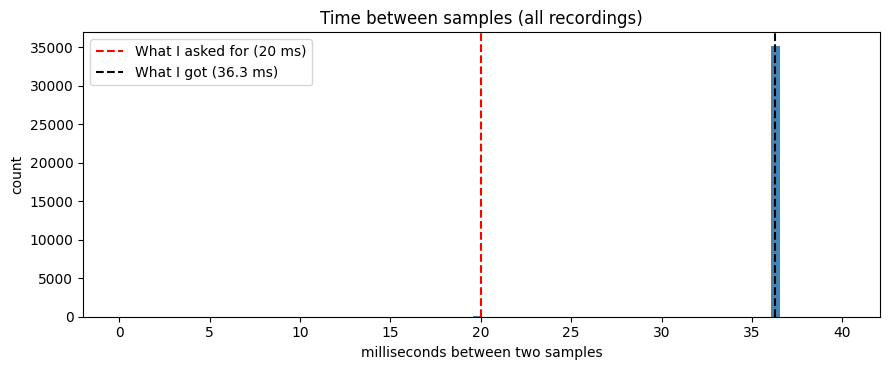

Real sampling rate (all recordings together): 27.55 Hz
Lowest and highest rate between recordings: 27.51 to 27.61 Hz
Biggest gap between two samples anywhere: 51.8 ms


In [4]:
all_dt = np.concatenate([np.diff(r["raw"]["seconds_elapsed"].values) * 1000 for r in recordings])
real_mean_ms = all_dt.mean()

plt.figure(figsize=(9, 3.8))
plt.hist(all_dt, bins=80, range=(0, np.percentile(all_dt, 99.9) * 1.1), color="steelblue")
plt.axvline(APP_SETTING_MS, color="red", linestyle="--", label=f"What I asked for ({APP_SETTING_MS} ms)")
plt.axvline(real_mean_ms, color="black", linestyle="--", label=f"What I got ({real_mean_ms:.1f} ms)")
plt.xlabel("milliseconds between two samples")
plt.ylabel("count")
plt.title("Time between samples (all recordings)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "sampling_intervals.png", dpi=150)
plt.show()

print(f"Real sampling rate (all recordings together): {1000 / real_mean_ms:.2f} Hz")
print(f"Lowest and highest rate between recordings: {recording_table['real_hz'].min()} to {recording_table['real_hz'].max()} Hz")
print(f"Biggest gap between two samples anywhere: {recording_table['max_gap_ms'].max()} ms")

### 5.1 What the sampling rate result shows

The phone gave about 27.5 Hz in every recording (between 27.51 and 27.61 Hz). I asked for 20 ms (50 Hz), but the average time between two samples was about 36.3 ms. So the phone is slower than what I asked for, but it is very steady. The spread of the time between samples is about 1 ms or less in every recording, and the biggest gap anywhere is 52 ms, which is only about 1.4 times the normal time. There are no long gaps where the phone stopped recording. This is why the histogram is just one thin tall bar at 36 ms: almost every sample came 36 ms after the one before it.

So my problem is not jitter or missing data. The only problem is that the real rate is different from the rate I asked for. I will report **27.5 Hz** as my real sampling rate. I used one phone for everything, so all recordings already have the same rate. I still convert everything to a clean 25 Hz grid in section 7, so every clip has exactly the same number of samples.

# 6. Plot the raw signals

I plot 10 seconds from the middle of one recording of each activity. I skip the first 20 seconds so the button pressing is not in the picture. The coloured lines are the three axes. The black line is the size of the acceleration, `sqrt(x² + y² + z²)`, which does not depend on how the phone is turned.

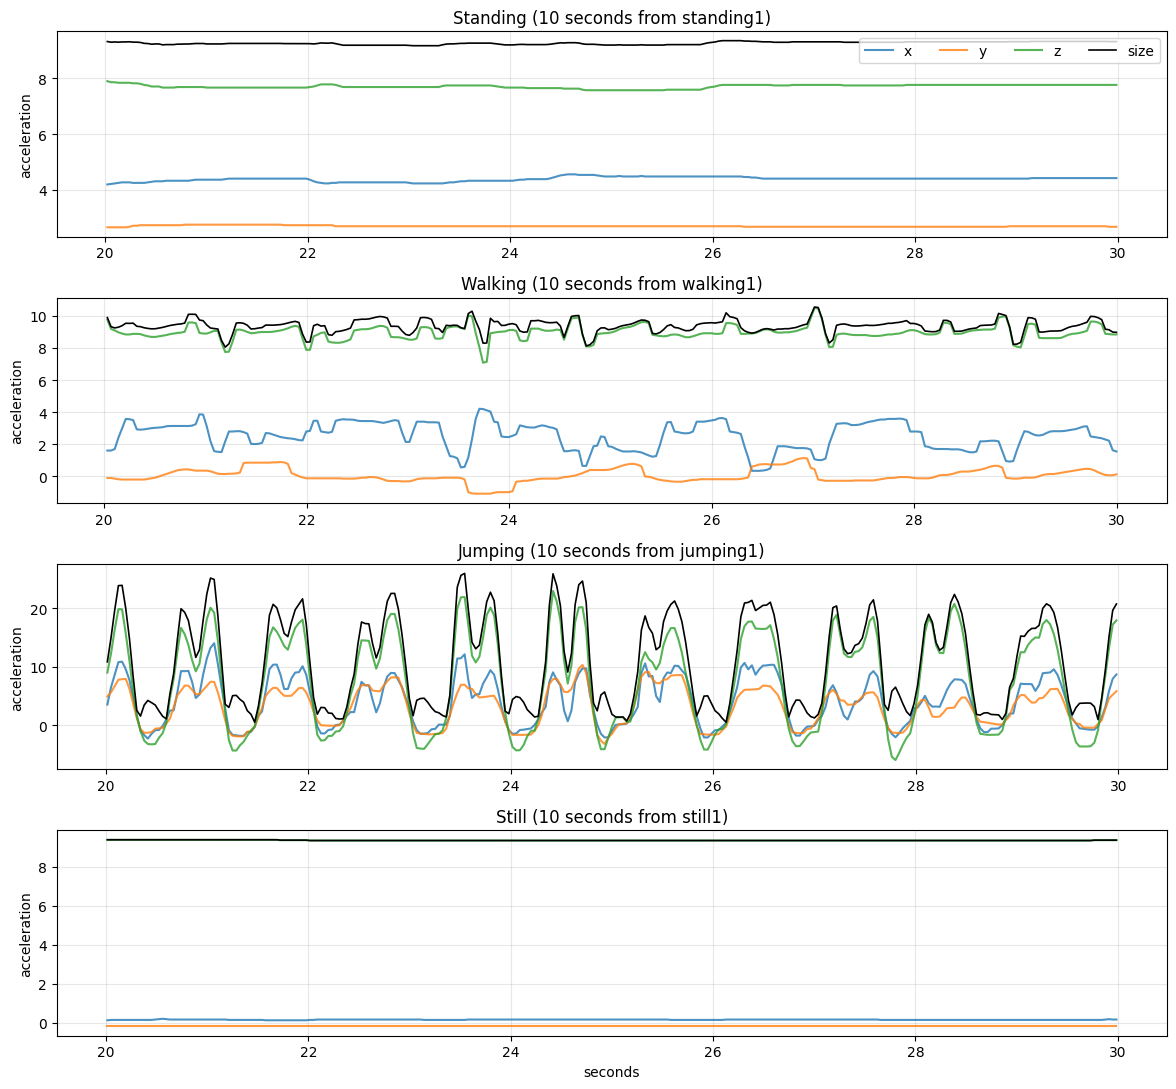

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(12, 11))
for ax, activity in zip(axes, ACTIVITIES):
    rec = next(r for r in recordings if r["activity"] == activity and r["rec_id"].endswith("1"))
    df = rec["raw"]
    part = df[(df["seconds_elapsed"] >= 20) & (df["seconds_elapsed"] < 30)]
    ax.plot(part["seconds_elapsed"], part["x"], label="x", alpha=0.8)
    ax.plot(part["seconds_elapsed"], part["y"], label="y", alpha=0.8)
    ax.plot(part["seconds_elapsed"], part["z"], label="z", alpha=0.8)
    ax.plot(part["seconds_elapsed"], np.sqrt(part["x"] ** 2 + part["y"] ** 2 + part["z"] ** 2),
            color="black", linewidth=1.2, label="size")
    ax.set_title(f"{activity.capitalize()} (10 seconds from {rec['rec_id']})")
    ax.set_ylabel("acceleration")
    ax.grid(True, alpha=0.3)
axes[0].legend(loc="upper right", ncol=4)
axes[-1].set_xlabel("seconds")
plt.tight_layout()
plt.savefig(FIG_DIR / "raw_signals.png", dpi=150)
plt.show()

### 6.1 What the raw signals show

The four activities already look very different, before any feature work.

- **Jumping** has big regular peaks. The size line goes up to about 20 to 25 and drops to almost 0, again and again, about every 0.6 seconds.
- **Walking** has a smaller and less regular pattern. The size line stays near 9 to 10 with small dips, one for each step.
- **Standing** is almost flat. The lines only move a little and slowly.
- **Still** is the flattest of all. The lines look like straight lines.

The black size line sits near 9.4 when I am standing or still. This is gravity, because Total Acceleration keeps gravity inside the signal. The three axes also show how the phone was held. When I stand, the phone is tilted a bit, so gravity is shared between x (about 4), y (about 2 to 3) and z (about 8). When the phone lies flat, almost all of gravity is on z (about 9.4) and x and y are close to 0. This helps, because standing and still would be very hard to separate if I only used the movement.

# 7. Make the sampling even and trim the ends

This is how I deal with the sampling rate. The same steps are used for every recording:

1. **One even time grid.** I make a grid with exactly 25 samples per second.
2. **Linear interpolation.** For every point on the grid I use the two nearest real samples to work out the value. After this every recording has the same rate and the same even spacing. This is also how I would fix a phone that runs at a different rate, because the same step brings it to the same `TARGET_HZ`.
3. **Trim.** I remove the first and last `TRIM_SECONDS` of each recording.

One limit: interpolation cannot invent data. If the phone had skipped a long time, the filled values would just be a straight line. My biggest gap is small (see section 5), so this is not a problem here. The signals I care about move slowly (under about 5 Hz), so going from 27.5 Hz to 25 Hz loses nothing important.

In [6]:
clip_len = int(round(CLIP_SECONDS * TARGET_HZ))
trim_len = int(round(TRIM_SECONDS * TARGET_HZ))

def make_even(df, hz):
    t = df["seconds_elapsed"].values
    grid = np.arange(t[0], t[-1], 1.0 / hz)
    out = pd.DataFrame({"timestamp": grid - grid[0]})
    for axis in ["x", "y", "z"]:
        out[axis] = np.interp(grid, t, df[axis].values)
    return out, grid[0]

for rec in recordings:
    even, start = make_even(rec["raw"], TARGET_HZ)
    rec["grid_start"] = start
    rec["even"] = even.iloc[trim_len: len(even) - trim_len].reset_index(drop=True)

print(f"Every recording is now at {TARGET_HZ} Hz, so one {CLIP_SECONDS} second clip has {clip_len} samples.")

Every recording is now at 25 Hz, so one 5 second clip has 125 samples.


To check that the conversion did not damage the signal, the plot below zooms into one second of a walking recording. The dots are the real samples from the phone. The line is the version on the even grid.

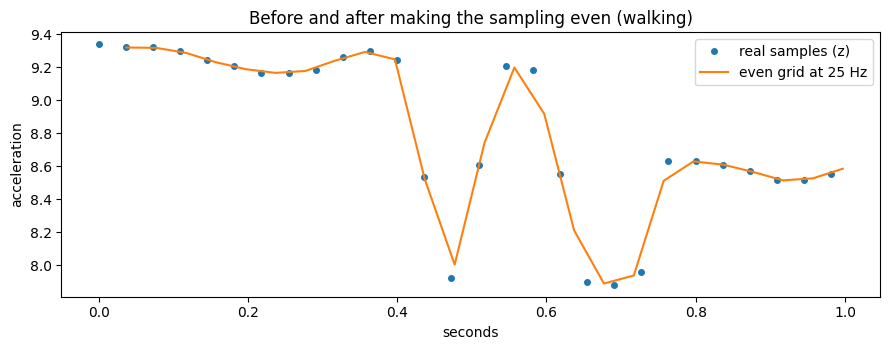

In [7]:
rec = next(r for r in recordings if r["activity"] == "walking" and r["rec_id"].endswith("1"))
raw = rec["raw"]
mid = raw["seconds_elapsed"].iloc[len(raw) // 2]
real_part = raw[(raw["seconds_elapsed"] >= mid) & (raw["seconds_elapsed"] < mid + 1.0)]
even_time = rec["grid_start"] + rec["even"]["timestamp"].values
even_mask = (even_time >= mid) & (even_time < mid + 1.0)

plt.figure(figsize=(9, 3.6))
plt.plot(real_part["seconds_elapsed"] - mid, real_part["z"], "o", markersize=4, label="real samples (z)")
plt.plot(even_time[even_mask] - mid, rec["even"]["z"].values[even_mask], "-", label=f"even grid at {TARGET_HZ} Hz")
plt.xlabel("seconds")
plt.ylabel("acceleration")
plt.title("Before and after making the sampling even (walking)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "resampling_zoom.png", dpi=150)
plt.show()

### 7.1 What the zoom shows

The line follows the shape of the dots. Every peak and dip in the real samples is also in the line, at about the same time and height. The dots are a little closer together than the points of the line, because the phone gives 27.5 samples per second and the grid has 25. So the conversion did not change the signal in any way that I can see.

# 8. Cut into clips and check every clip

Now I cut each recording into clips of `CLIP_SECONDS`. A clip that is shorter than the full length at the end is thrown away, so every clip has the same number of samples.

Before I save the clips I check them. A long recording can have parts that do not look like the activity. For example, at the end of a jumping recording I stopped jumping a bit before I pressed the stop button. Or at the end of a standing recording I moved my hand to reach the phone. These parts would give wrong labels.

My check is simple. For every clip I measure how shaky it is (the standard deviation of the acceleration size). Then I compare it with the usual clip from the same recording (the median):

- If a clip is **more than 3 times** as shaky as the usual clip, something extra happened, like picking up the phone. I drop it.
- If the activity is a moving one (usual shakiness above 0.5) and the clip is **less than 0.4 times** as shaky, I probably stopped moving. I drop it.

I do not use the second rule for Standing and Still, because they are calm on purpose.

In [8]:
clip_rows = []
for rec in recordings:
    even = rec["even"]
    mag = np.sqrt(even["x"] ** 2 + even["y"] ** 2 + even["z"] ** 2).values
    n_clips = len(even) // clip_len
    stds = np.array([mag[i * clip_len:(i + 1) * clip_len].std() for i in range(n_clips)])
    usual = np.median(stds)
    for i in range(n_clips):
        too_busy = stds[i] > TOO_BUSY_FACTOR * usual
        too_calm = (usual > MOVING_LEVEL) and (stds[i] < TOO_CALM_FACTOR * usual)
        clip_rows.append({
            "rec_id": rec["rec_id"],
            "activity": rec["activity"],
            "split": rec["split"],
            "clip_in_recording": i,
            "start_s": TRIM_SECONDS + i * CLIP_SECONDS,
            "std": stds[i],
            "usual_std": usual,
            "keep": not (too_busy or too_calm),
            "reason": "too busy" if too_busy else ("too calm" if too_calm else ""),
        })
clip_table = pd.DataFrame(clip_rows)

dropped = clip_table[~clip_table["keep"]]
print(f"Clips cut: {len(clip_table)}   kept: {int(clip_table['keep'].sum())}   dropped: {len(dropped)}")
dropped[["rec_id", "start_s", "std", "usual_std", "reason"]].round(3)

Clips cut: 246   kept: 242   dropped: 4


,rec_id,start_s,std,usual_std,reason
70,standing2,101,0.163,0.022,too busy
86,standing3,76,0.131,0.019,too busy
113,standing1,131,0.122,0.029,too busy
191,still1,181,0.042,0.009,too busy


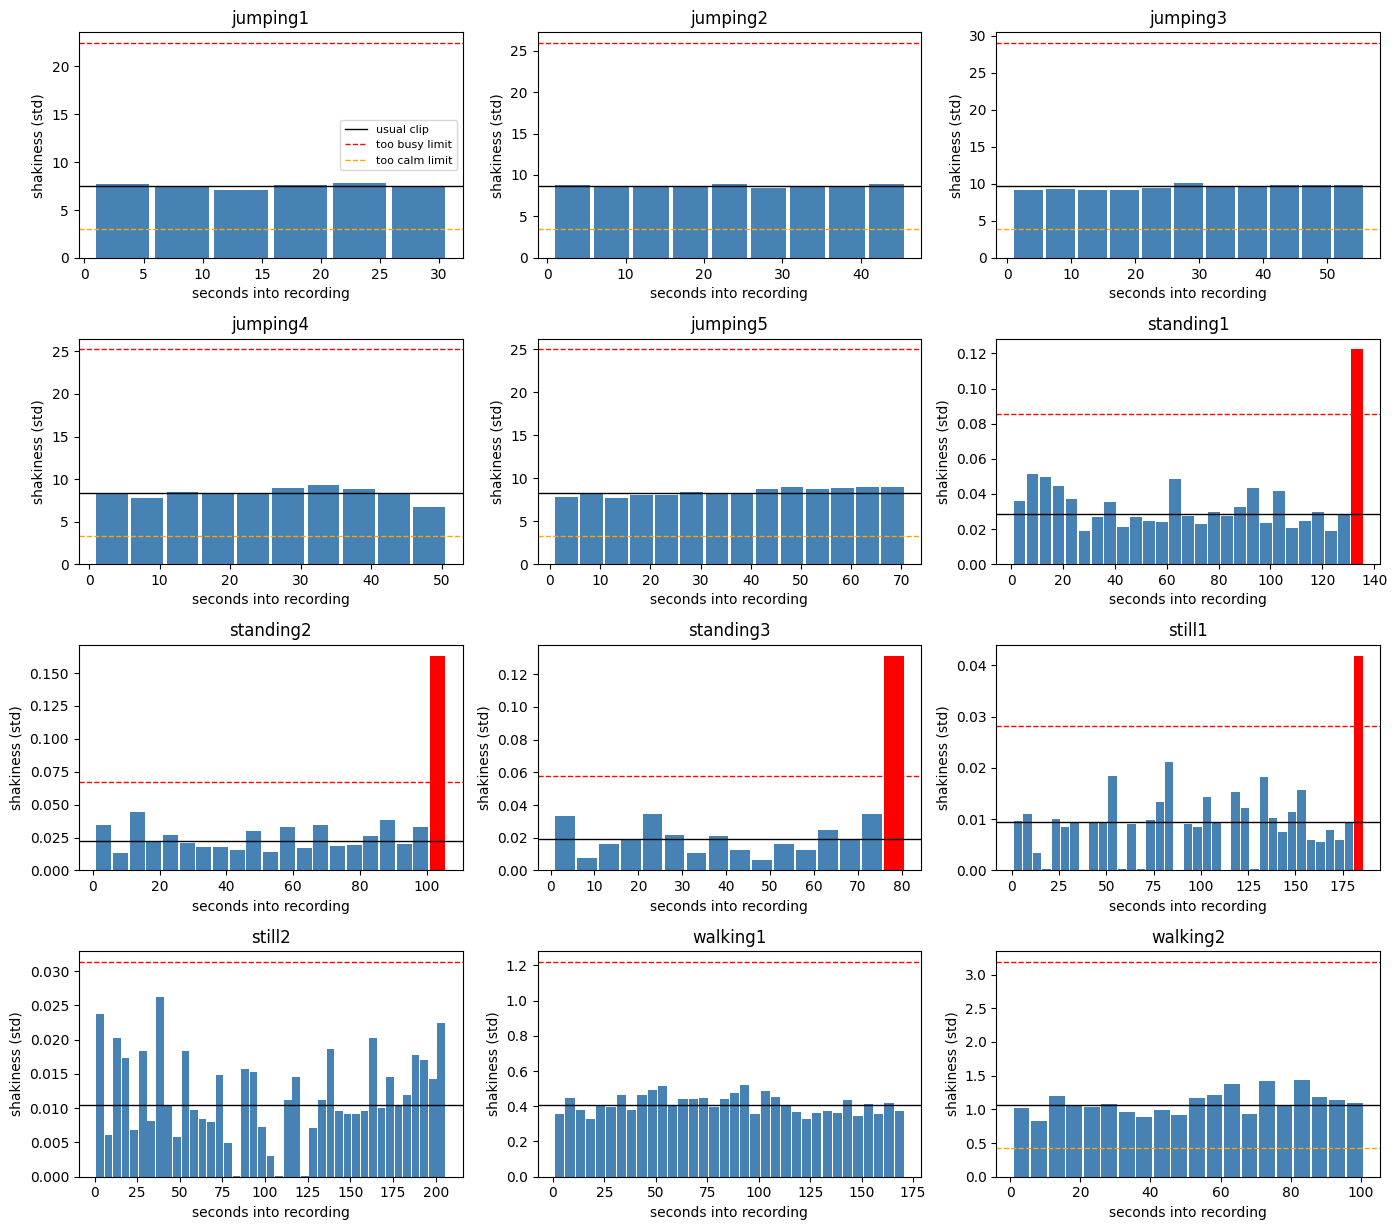

In [9]:
rec_ids = [r["rec_id"] for r in sorted(recordings, key=lambda r: r["rec_id"])]
n_cols = 3
n_rows = int(np.ceil(len(rec_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.1 * n_rows), squeeze=False)
for ax, rec_id in zip(axes.ravel(), rec_ids):
    part = clip_table[clip_table["rec_id"] == rec_id]
    usual = part["usual_std"].iloc[0]
    colors = np.where(part["keep"], "steelblue", "red")
    ax.bar(part["start_s"], part["std"], width=CLIP_SECONDS * 0.9, align="edge", color=colors)
    ax.axhline(usual, color="black", linewidth=1, label="usual clip")
    ax.axhline(usual * TOO_BUSY_FACTOR, color="red", linestyle="--", linewidth=1, label="too busy limit")
    if usual > MOVING_LEVEL:
        ax.axhline(usual * TOO_CALM_FACTOR, color="orange", linestyle="--", linewidth=1, label="too calm limit")
    ax.set_title(rec_id)
    ax.set_xlabel("seconds into recording")
    ax.set_ylabel("shakiness (std)")
for ax in axes.ravel()[len(rec_ids):]:
    ax.axis("off")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "clip_check.png", dpi=150)
plt.show()

### 8.1 What the clip check shows

I cut 246 clips and the check dropped 4 of them, so 242 clips are kept. Three of the dropped clips were the last clip of a recording (standing1, standing2 and still1). I was probably reaching for the phone to press stop, so these clips were shakier (0.12, 0.16 and 0.04) than the usual clip of the same recording (0.03, 0.02 and 0.01). The fourth one is in the middle of standing3 (at 76 seconds). It has a shakiness of 0.13 against 0.02 for the usual clip, so I probably moved during that part. They are the red bars in the plot.

All the jumping and walking bars are close to the usual clip, and none of them is near the red or orange limits. So the "too calm" rule did not drop anything. One thing I should say honestly: at the end of jumping2 and jumping3 I stopped jumping about 2 seconds before I pressed stop, and at the end of jumping5 I slowed down. These calm parts were not caught by the rule. They were removed anyway, because the leftover piece at the end of each recording is shorter than 5 seconds and is thrown away. That was luck, so for new recordings I will keep the check turned on.

# 9. Save the clips as labelled files

Each kept clip is saved as its own csv file. The folder tells the split (train or test) and the activity, and the file name tells the activity and a number, for example `dataset/train/walking/walking_007.csv`. Every file has a `timestamp` column that starts at 0, the three axes, and an `activity` column with the label.

I also save a table called `manifest.csv` that lists every file and which recording it came from. This is how I can show that test clips never come from a training recording.

In [10]:
for old in DATASET_DIR.rglob("*.csv"):
    old.unlink()

counters = {}
manifest_rows = []
for rec in recordings:
    even = rec["even"]
    keep_table = clip_table[(clip_table["rec_id"] == rec["rec_id"]) & clip_table["keep"]]
    for _, row in keep_table.iterrows():
        i = int(row["clip_in_recording"])
        chunk = even.iloc[i * clip_len:(i + 1) * clip_len].copy()
        chunk["timestamp"] = chunk["timestamp"] - chunk["timestamp"].iloc[0]
        chunk = chunk.rename(columns={"x": "acc_x", "y": "acc_y", "z": "acc_z"})
        chunk["activity"] = rec["activity"]

        key = (rec["split"], rec["activity"])
        counters[key] = counters.get(key, 0) + 1
        out_dir = DATASET_DIR / rec["split"] / rec["activity"]
        out_dir.mkdir(parents=True, exist_ok=True)
        file_path = out_dir / f"{rec['activity']}_{counters[key]:03d}.csv"
        chunk.to_csv(file_path, index=False, float_format="%.5f")

        manifest_rows.append({
            "file": file_path.relative_to(DATASET_DIR).as_posix(),
            "split": rec["split"],
            "activity": rec["activity"],
            "source_recording": rec["rec_id"],
            "start_in_recording_s": row["start_s"],
            "samples": len(chunk),
            "real_hz_of_source": round(rec["stats"]["real_hz"], 2),
        })

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(DATASET_DIR / "manifest.csv", index=False)
print(f"Saved {len(manifest)} clip files of {CLIP_SECONDS} seconds each at {TARGET_HZ} Hz.")
manifest.head()

Saved 242 clip files of 5 seconds each at 25 Hz.


,file,split,activity,source_recording,start_in_recording_s,samples,real_hz_of_source
0,test/jumping/jumping_001.csv,test,jumping,jumping2,1,125,27.61
1,test/jumping/jumping_002.csv,test,jumping,jumping2,6,125,27.61
2,test/jumping/jumping_003.csv,test,jumping,jumping2,11,125,27.61
3,test/jumping/jumping_004.csv,test,jumping,jumping2,16,125,27.61
4,test/jumping/jumping_005.csv,test,jumping,jumping2,21,125,27.61


# 10. How much data do I have?

Now I count the files and the seconds for each activity and compare them with the targets from the settings cell. The test files are counted separately, because they stay unseen. The total columns count everything in the dataset folder.

In [11]:
def count_table():
    rows = []
    for activity in ACTIVITIES:
        part = manifest[manifest["activity"] == activity]
        train_files = int((part["split"] == "train").sum())
        test_files = int((part["split"] == "test").sum())
        total_files = train_files + test_files
        cut = clip_table[clip_table["activity"] == activity]
        rows.append({
            "activity": activity,
            "recordings": int(part["source_recording"].nunique()),
            "train_files": train_files,
            "test_files": test_files,
            "total_files": total_files,
            "total_seconds": total_files * CLIP_SECONDS,
            "clips_dropped": int((~cut["keep"]).sum()),
            "has_90_seconds": total_files * CLIP_SECONDS >= MIN_SECONDS_PER_ACTIVITY,
            "has_50_files": total_files >= TARGET_FILES_PER_ACTIVITY,
        })
    return pd.DataFrame(rows)

counts = count_table()
counts

,activity,recordings,train_files,test_files,total_files,total_seconds,clips_dropped,has_90_seconds,has_50_files
0,standing,3,41,20,61,305,3,True,True
1,walking,2,34,20,54,270,0,True,True
2,jumping,5,41,9,50,250,0,True,True
3,still,2,36,41,77,385,1,True,True


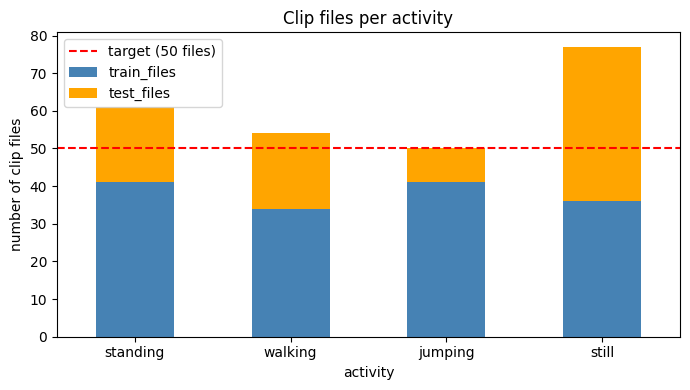

In [12]:
plot_data = counts.set_index("activity")[["train_files", "test_files"]]
ax = plot_data.plot(kind="bar", stacked=True, figsize=(7, 4), color=["steelblue", "orange"])
ax.axhline(TARGET_FILES_PER_ACTIVITY, color="red", linestyle="--", label=f"target ({TARGET_FILES_PER_ACTIVITY} files)")
ax.set_ylabel("number of clip files")
ax.set_title("Clip files per activity")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "files_per_activity.png", dpi=150)
plt.show()

### 10.1 What the counts show

I have 242 clip files in total: 152 for training and 90 for testing.

- **Still:** 77 files (385 seconds). Above both targets.
- **Standing:** 61 files (305 seconds). Above both targets.
- **Walking:** 54 files (270 seconds). Above both targets.
- **Jumping:** 50 files (250 seconds). Exactly on the target, with nothing spare.

All four activities pass the 1 minute 30 seconds minimum and the 50 file target when I count the whole dataset. Jumping is exactly at 50, so if one jumping clip is dropped in the future, it will fall below. Jumping has 41 training files (205 seconds).

The test set is uneven (41 test clips for still and only 9 for jumping). I must remember this when I read the accuracy later. Before training I will use the same number of windows from each activity, so the model is not pulled toward the biggest class.

# 11. Look at the clips

Before I build anything, I plot one clip of each activity. The left plots show the three axes. The right plots show the size of the acceleration with its average removed, so I can see the small movements without the big constant pull of gravity. If I cannot see a difference here, the model will find it hard too.

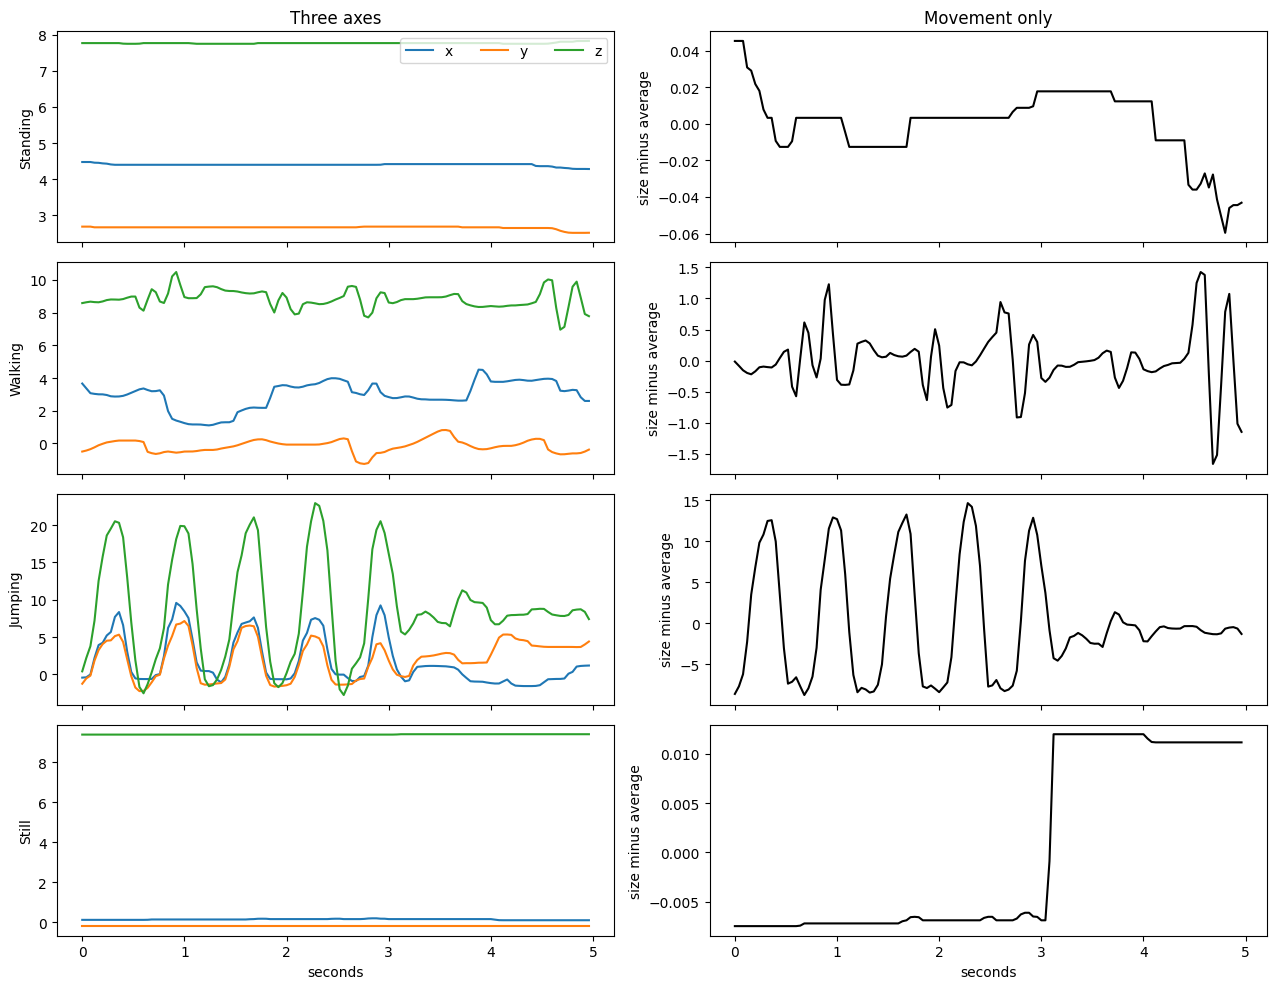

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(13, 10), sharex=True)
for row, activity in enumerate(ACTIVITIES):
    files = manifest[(manifest["activity"] == activity) & (manifest["split"] == "train")]["file"].tolist()
    clip = pd.read_csv(DATASET_DIR / files[len(files) // 2])
    for col in ["acc_x", "acc_y", "acc_z"]:
        axes[row, 0].plot(clip["timestamp"], clip[col], label=col[-1])
    size = np.sqrt(clip["acc_x"] ** 2 + clip["acc_y"] ** 2 + clip["acc_z"] ** 2)
    axes[row, 1].plot(clip["timestamp"], size - size.mean(), color="black")
    axes[row, 0].set_ylabel(activity.capitalize())
    axes[row, 1].set_ylabel("size minus average")
axes[0, 0].set_title("Three axes")
axes[0, 1].set_title("Movement only")
axes[0, 0].legend(loc="upper right", ncol=3)
axes[-1, 0].set_xlabel("seconds")
axes[-1, 1].set_xlabel("seconds")
plt.tight_layout()
plt.savefig(FIG_DIR / "sample_clips.png", dpi=150)
plt.show()

In [14]:
def dominant_frequency(size, hz):
    size = size - size.mean()
    spectrum = np.abs(fft(size))[: len(size) // 2]
    freqs = fftfreq(len(size), 1.0 / hz)[: len(size) // 2]
    return freqs[1:][spectrum[1:].argmax()]

clip_stats = []
for _, row in manifest.iterrows():
    clip = pd.read_csv(DATASET_DIR / row["file"])
    size = np.sqrt(clip["acc_x"] ** 2 + clip["acc_y"] ** 2 + clip["acc_z"] ** 2).values
    clip_stats.append({
        "activity": row["activity"],
        "mean_size": size.mean(),
        "std_size": size.std(),
        "dominant_hz": dominant_frequency(size, TARGET_HZ),
    })
clip_stats = pd.DataFrame(clip_stats)

activity_summary = clip_stats.groupby("activity").agg(
    mean_size=("mean_size", "median"),
    std_size=("std_size", "median"),
    dominant_hz=("dominant_hz", "median"),
).reindex(ACTIVITIES).round(3)
activity_summary

,mean_size,std_size,dominant_hz
activity,,,
standing,9.381,0.025,0.2
walking,9.373,0.457,1.6
jumping,10.596,8.625,1.6
still,9.372,0.010,0.2


### 11.1 What the clips show

The clips match what the raw signals showed.

- **Jumping:** a clear repeating peak, about 8 of them in 5 seconds (around 1.6 per second). It is by far the biggest movement (median shakiness 8.7).
- **Walking:** smaller and less regular bumps (median shakiness 0.46). That is about 19 times calmer than jumping.
- **Standing and Still:** almost flat. Standing has a median shakiness of 0.025 and still has 0.010. Standing is about 2.5 times shakier than still, but the ranges overlap (standing 0.006 to 0.052, still 0 to 0.026).

The table shows one more thing. Walking and jumping have the same dominant frequency (1.6 Hz), so the frequency alone cannot separate them. The size of the movement can (0.46 against 8.7). For standing and still, the dominant frequency (0.2 Hz) is only the lowest bin of the FFT. It does not tell anything real, because there is no steady rhythm in these two.

Standing and Still look the most alike, as I expected. Because the shakiness ranges overlap, what separates them best is the average of the axes. For still, z is around 9.4 and x and y are close to 0, because the phone is flat. For standing, x is about 2 and y about 1.6, and z is between 7.7 and 9.3. I need to be honest here: this comes from how I held the phone and not only from the activity. The tilt is not the same in all my standing recordings, so the model may find these two harder than the numbers suggest.

# 12. Choose the window size

The HMM does not look at every single sample. It looks at one feature vector for each short window of the signal. So I need to choose how long a window is, and I base the choice on the sampling rate:

- **Number of samples.** A window of `WINDOW_SECONDS` at `TARGET_HZ` has `WINDOW_SECONDS x TARGET_HZ` samples.
- **Enough movement inside.** From the table in section 11, walking and jumping repeat about once or twice every second. The window should hold at least two repeats, so it can see a pattern and not just a single bump.
- **Enough frequency detail.** The FFT can only separate frequencies that are `1 / window length` apart. A 2 second window gives steps of 0.5 Hz.
- **Not too long.** A longer window blurs the moment where the activity changes, and gives fewer windows per clip.
- **Overlap.** Windows overlap by half, so I get more observations from the same clip and no moment sits only at the edge of a window.
- **Edges.** Windows are made inside one clip. A window never crosses from one clip into the next.

The table compares a few window sizes at 25 Hz.

In [15]:
walking_hz = activity_summary.loc["walking", "dominant_hz"]
jumping_hz = activity_summary.loc["jumping", "dominant_hz"]

options = []
for w in [0.5, 1.0, 2.0, 3.0, 5.0]:
    win = int(round(w * TARGET_HZ))
    step = max(1, int(round(win * (1 - WINDOW_OVERLAP))))
    options.append({
        "window_seconds": w,
        "samples_per_window": win,
        "frequency_step_hz": round(1.0 / w, 2),
        "highest_frequency_hz": TARGET_HZ / 2,
        "walking_repeats_inside": round(w * walking_hz, 1),
        "jumping_repeats_inside": round(w * jumping_hz, 1),
        "windows_per_clip": (clip_len - win) // step + 1 if clip_len >= win else 0,
    })
pd.DataFrame(options)

,window_seconds,samples_per_window,frequency_step_hz,highest_frequency_hz,walking_repeats_inside,jumping_repeats_inside,windows_per_clip
0,0.5,12,2.00,12.5,0.8,0.8,19
1,1.0,25,1.00,12.5,1.6,1.6,9
2,2.0,50,0.50,12.5,3.2,3.2,4
3,3.0,75,0.33,12.5,4.8,4.8,2
4,5.0,125,0.20,12.5,8.0,8.0,1


In [16]:
WINDOW_LEN = int(round(WINDOW_SECONDS * TARGET_HZ))
STEP_LEN = max(1, int(round(WINDOW_LEN * (1 - WINDOW_OVERLAP))))

def make_windows(values, win_len, step_len):
    n = (len(values) - win_len) // step_len + 1
    if n <= 0:
        return np.empty((0, win_len, values.shape[1]))
    return np.stack([values[i * step_len: i * step_len + win_len] for i in range(n)])

SENSOR_COLS = ["acc_x", "acc_y", "acc_z"]
window_rows = []
for _, row in manifest.iterrows():
    clip = pd.read_csv(DATASET_DIR / row["file"])
    windows = make_windows(clip[SENSOR_COLS].values, WINDOW_LEN, STEP_LEN)
    window_rows.append({"split": row["split"], "activity": row["activity"], "windows": len(windows)})

window_counts = (pd.DataFrame(window_rows).groupby(["activity", "split"])["windows"].sum()
                 .unstack("split").fillna(0).astype(int).reindex(ACTIVITIES))
print(f"Window length: {WINDOW_LEN} samples ({WINDOW_SECONDS} seconds at {TARGET_HZ} Hz), step: {STEP_LEN} samples")
window_counts

Window length: 50 samples (2.0 seconds at 25 Hz), step: 25 samples


split,test,train
activity,,
standing,80,164
walking,80,136
jumping,36,164
still,164,144


### 12.1 What the window choice shows

At 25 Hz my 2 second window has 50 samples. From the table, walking and jumping both repeat about 1.6 times per second, so a 2 second window holds about 3 repeats. That is enough to see a pattern. A 1 second window would hold only 1.6 repeats and a 0.5 second window less than one, so those are too short. The 2 second window gives frequency steps of 0.5 Hz in the FFT. This is not very fine, but it is good enough, because the main frequency I care about (about 1.6 Hz) is far from the quiet activities (close to 0). A 3 second window would give finer steps (0.33 Hz) but only 2 windows per clip, and 5 seconds would give only 1 window per clip.

I use 2 seconds with 50 percent overlap. This gives 4 windows from each 5 second clip: 608 windows for training and 360 for testing. Walking has the fewest windows for training (136) and still has the most in the test set (164).

# 13. Save the dataset for the repository

The last step of this part packs the `dataset` folder into one zip file, so I can download it and put it in the GitHub repository. A short readme is added inside the folder.

In [17]:
readme = f"""# Activity dataset

Phone accelerometer recordings (Total Acceleration, gravity included) of four activities:
standing, walking, jumping and still. Recorded with the Sensor Logger app on one Android phone
held at waist level. The phone has no gyroscope.

- Real sampling rate of the phone: about {1000 / real_mean_ms:.1f} Hz (asked for 50 Hz, the phone gave less).
- Every clip was converted to an even {TARGET_HZ} Hz grid.
- Every clip is {CLIP_SECONDS} seconds long ({clip_len} samples) and was cut from a longer recording.
- train/ and test/ are made from different recordings, so the test clips are unseen.
- manifest.csv lists every file and the recording it came from.

Columns: timestamp (seconds, starts at 0), acc_x, acc_y, acc_z, activity.
"""
(DATASET_DIR / "README.md").write_text(readme)

archive = shutil.make_archive(str(OUT_ROOT / "activity_dataset"), "zip", DATASET_DIR)
print("Saved:", archive)

Saved: /kaggle/working/activity_dataset.zip


# 14. Build the windows

From here on the model works with windows and not with whole clips. I cut every clip into windows of 2 seconds that move forward by 1 second (so they overlap by half), as chosen in section 12. For every window I also keep where it came from: the split, the activity, the recording and the time in that recording. I need this later to put the windows back in time order for the HMM, and to be sure that no test window comes from a training recording.

In [18]:

window_data = []
window_info = []
for _, row in manifest.iterrows():
    clip = pd.read_csv(DATASET_DIR / row["file"])
    clip_windows = make_windows(clip[SENSOR_COLS].values, WINDOW_LEN, STEP_LEN)
    for k, window in enumerate(clip_windows):
        window_data.append(window)
        window_info.append({
            "clip_file": row["file"],
            "split": row["split"],
            "activity": row["activity"],
            "recording": row["source_recording"],
            "start_s": row["start_in_recording_s"] + k * STEP_LEN / TARGET_HZ,
        })

window_data = np.stack(window_data)
window_info = pd.DataFrame(window_info)
print("Windows:", window_data.shape, "(windows, samples, axes)")
window_info.groupby(["split", "activity"]).size().unstack("split")

Windows: (968, 50, 3) (windows, samples, axes)


split,test,train
activity,,
jumping,36,164
standing,80,164
still,164,144
walking,80,136


# 15. Features

For every window I compute 14 features. 10 of them are from the time domain and 4 are from the frequency domain (they come from the FFT). I made the choice by looking at the plots in sections 6 and 11: the activities differ in how strong the movement is, how fast it repeats, and how the phone is held.

I use the **size** of the acceleration, `sqrt(x² + y² + z²)`, for most features, because it does not depend on how the phone is turned. "Size without its average" means the size minus its own average over the window. That removes gravity and keeps only the movement.

| Feature | Domain | What it measures | Why it helps |
|---|---|---|---|
| `mean_x`, `mean_y`, `mean_z` | time | Average of each axis | Shows how gravity is shared between the axes, so it shows how the phone is tilted. Still (flat) and standing (tilted) get different values. It depends on how I hold the phone, so I keep these three in their own group |
| `log_std` | time | Standard deviation of the size | How strong the movement is. Jumping is far above walking, and walking is far above standing and still |
| `log_sma` | time | Signal magnitude area: average of the absolute movement of the three axes | Also shows the strength of the movement, but counts every axis. It still works if only one axis moves |
| `log_range` | time | Highest minus lowest size | The height of the peaks. Jumping has high peaks |
| `corr_xy`, `corr_xz`, `corr_yz` | time | How much two axes move together | In jumping the axes move together, in walking they are more mixed |
| `zero_cross_rate` | time | How many times per second the size without its average crosses zero | A simple measure of how fast the movement repeats |
| `dominant_hz` | frequency | The strongest frequency in the FFT | The rhythm of the movement, steps or jumps per second |
| `log_energy_low` | frequency | FFT power between 0.5 and 3 Hz | This is where steps and jumps are |
| `log_energy_high` | frequency | FFT power above 3 Hz | Sharp hits, like landing, and small shaking |
| `spectral_entropy` | frequency | How spread out the FFT power is (0 is one clean peak, 1 is flat) | A rhythmic movement has a clean peak. Noise is spread out |

The features that start with `log_` are put on a log scale. The standard deviation goes from about 0.01 (still) to about 9 (jumping), so without the log the quiet activities would all look like zero. A small floor is added before the log so that a window with no movement at all does not give minus infinity.

Before the FFT the window is multiplied by a Hann window, which fades the two ends to zero. This reduces the leakage that comes from cutting a signal at a random place. The FFT is padded with zeros to 256 points. This does not add real detail (the real step is still 0.5 Hz), but it lets the peak be placed more smoothly.

In [19]:
LOW_BAND = (0.5, 3.0)
MIN_FEATURE_HZ = 0.5
NFFT = 256
LOG_FLOOR = 1e-4

FEATURE_NAMES = [
    "mean_x", "mean_y", "mean_z",
    "log_std", "log_sma", "log_range",
    "corr_xy", "corr_xz", "corr_yz",
    "zero_cross_rate",
    "dominant_hz", "log_energy_low", "log_energy_high", "spectral_entropy",
]
TIME_FEATURES = FEATURE_NAMES[:10]
FREQUENCY_FEATURES = FEATURE_NAMES[10:]
ORIENTATION_FEATURES = ["mean_x", "mean_y", "mean_z"]
MOTION_FEATURES = [f for f in FEATURE_NAMES if f not in ORIENTATION_FEATURES]

def safe_corr(a, b):
    if a.std() < 1e-6 or b.std() < 1e-6:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1])

def window_features(window, hz):
    x, y, z = window[:, 0], window[:, 1], window[:, 2]
    size = np.sqrt(x ** 2 + y ** 2 + z ** 2)
    moving = size - size.mean()
    centred = window - window.mean(axis=0)

    crossings = np.sum(moving[:-1] * moving[1:] < 0)
    duration = len(window) / hz

    power = np.abs(fft(moving * np.hanning(len(moving)), n=NFFT)[: NFFT // 2 + 1]) ** 2 / len(moving)
    freqs = np.abs(fftfreq(NFFT, 1.0 / hz)[: NFFT // 2 + 1])
    usable = freqs >= MIN_FEATURE_HZ
    low = (freqs >= LOW_BAND[0]) & (freqs < LOW_BAND[1])
    high = freqs >= LOW_BAND[1]
    share = power[usable] + 1e-12
    share = share / share.sum()

    return [
        x.mean(), y.mean(), z.mean(),
        np.log10(size.std() + LOG_FLOOR),
        np.log10(np.abs(centred).sum(axis=1).mean() + LOG_FLOOR),
        np.log10(size.max() - size.min() + LOG_FLOOR),
        safe_corr(x, y), safe_corr(x, z), safe_corr(y, z),
        crossings / duration,
        freqs[usable][power[usable].argmax()],
        np.log10(power[low].sum() + LOG_FLOOR),
        np.log10(power[high].sum() + LOG_FLOOR),
        float(-(share * np.log(share)).sum() / np.log(len(share))),
    ]

features = pd.DataFrame(
    [window_features(w, TARGET_HZ) for w in window_data], columns=FEATURE_NAMES
)
feature_table = pd.concat([window_info, features], axis=1)
feature_table.to_csv(OUT_ROOT / "features.csv", index=False)

print("Missing values:", int(features.isna().sum().sum()))
print("Time features:", len(TIME_FEATURES), " Frequency features:", len(FREQUENCY_FEATURES))
feature_table.groupby("activity")[FEATURE_NAMES].median().reindex(ACTIVITIES).round(2).T

Missing values: 0
Time features: 10  Frequency features: 4


activity,standing,walking,jumping,still
mean_x,2.04,2.78,1.91,0.11
mean_y,1.65,0.10,0.34,-0.13
mean_z,8.99,8.86,8.80,9.37
log_std,-1.72,-0.32,0.94,-3.03
log_sma,-1.29,0.15,1.09,-1.90
log_range,-1.17,0.35,1.42,-2.22
corr_xy,0.00,0.05,0.88,0.00
corr_xz,-0.28,-0.26,0.86,0.00
corr_yz,-0.06,0.18,0.81,0.00
zero_cross_rate,1.50,4.00,3.50,0.50


### 15.1 What the feature table shows

There are no missing values: 14 features for each of the 968 windows. The table shows the middle value (median) of every feature for each activity, and it already tells a story.

- **Movement strength** (`log_std`, `log_sma`, `log_range` and the two energies) goes up in a clear order: still, standing, walking, jumping. For `log_std` the values are -3.0, -1.7, -0.3 and 0.9. This is a log scale, so jumping is thousands of times stronger than still. A typical still window has a standard deviation of about 0.001.
- **Orientation:** still has `mean_x` and `mean_y` close to 0 and `mean_z` at 9.4, because the phone lies flat. In the other three the phone is tilted, so gravity is spread over the axes.
- **Correlation:** only jumping has high correlation between the axes (0.8 to 0.9). Standing and walking are between -0.3 and 0.2. For still the value is exactly 0, but this is a rule I chose: when an axis does not move at all, the correlation cannot be calculated, so I set it to 0. It is not a real measurement.
- **Rhythm:** `dominant_hz` is 1.6 for walking and 1.7 for jumping. For standing and still it is 0.59, which is the lowest frequency I allow, so it only says "no clear rhythm". `zero_cross_rate` is highest for walking (4.0 per second) and lower for jumping (3.5). I think walking has small extra bumps between the main ones, so it crosses zero more often, but I did not check this directly.
- **Spectral entropy** is almost the same for standing, jumping and still (0.63 to 0.64). Only walking is different (0.77). It looks like a weak feature.

# 16. Look at the features for each activity

A feature is only useful if its values are different for different activities. The boxplots below show every feature for the training windows, one box for each activity. A box that is far from the others means the feature can separate that activity. Boxes that sit on top of each other mean the feature cannot tell those activities apart.

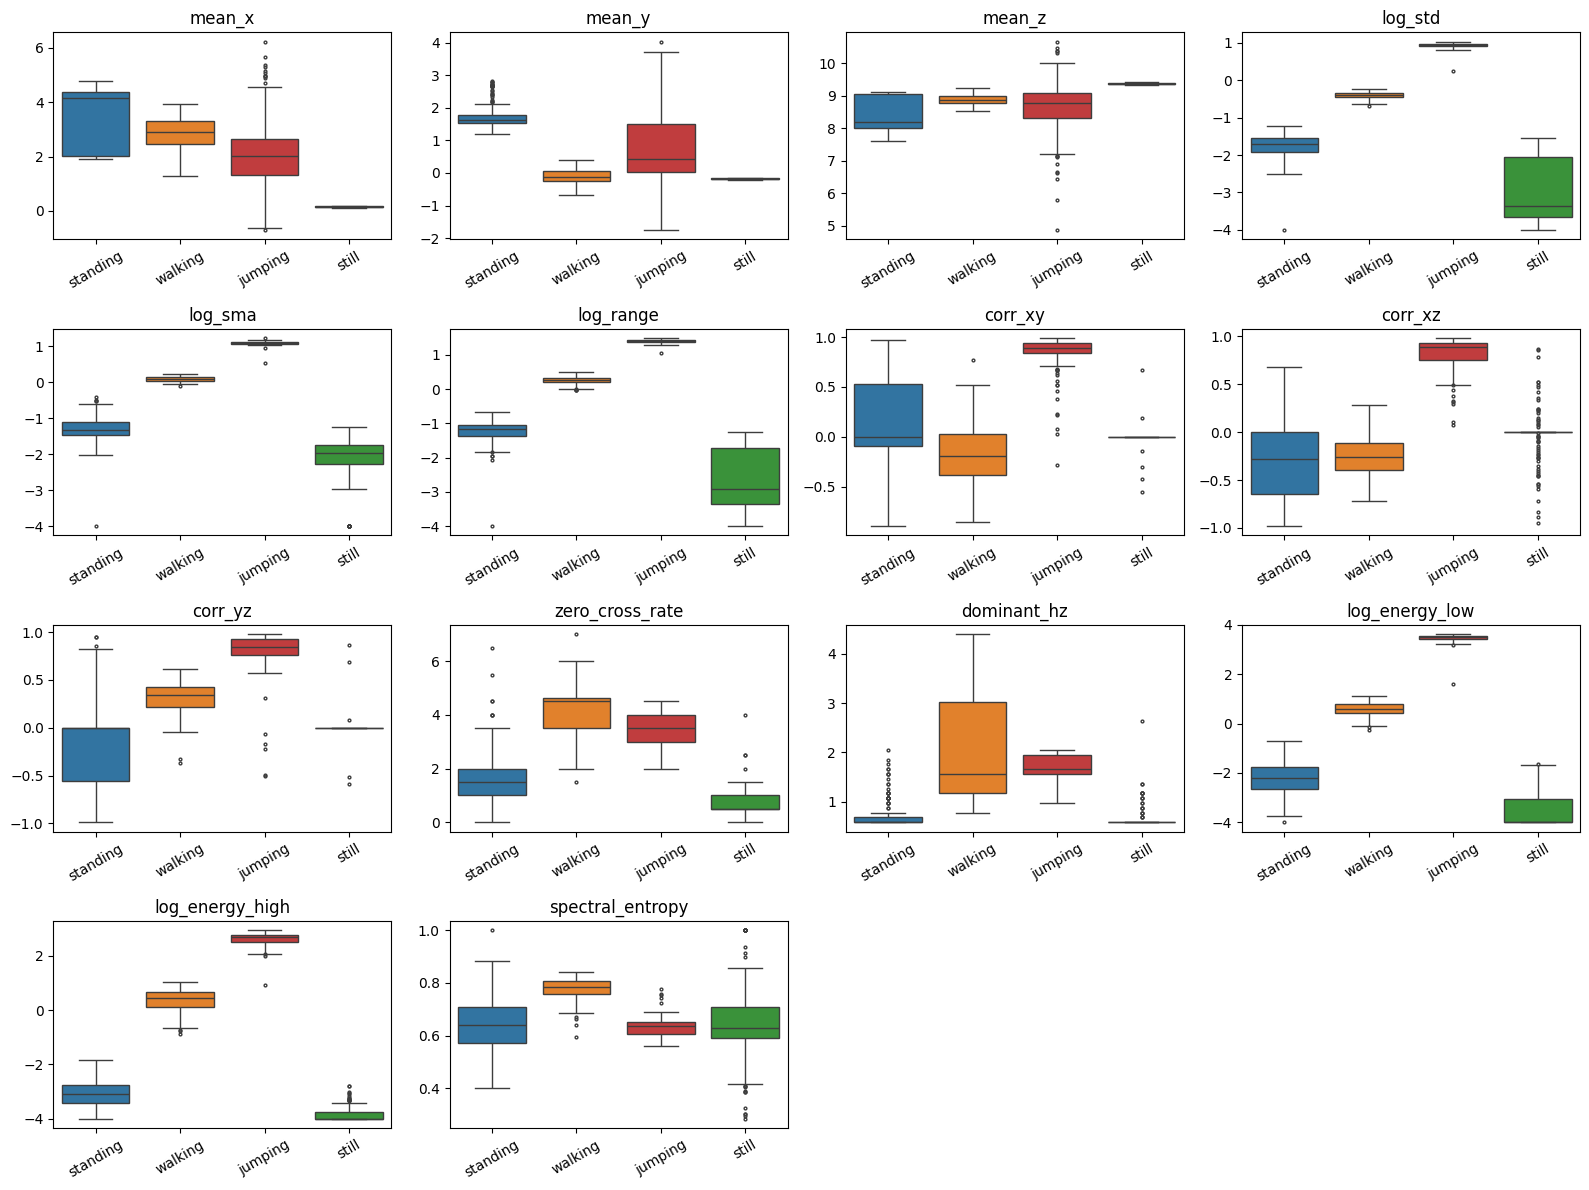

In [20]:
train_features = feature_table[feature_table["split"] == "train"]
palette = dict(zip(ACTIVITIES, ["tab:blue", "tab:orange", "tab:red", "tab:green"]))

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, name in zip(axes.ravel(), FEATURE_NAMES):
    sns.boxplot(data=train_features, x="activity", y=name, order=ACTIVITIES, palette=palette, ax=ax, fliersize=2)
    ax.set_title(name)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelrotation=30)
for ax in axes.ravel()[len(FEATURE_NAMES):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_boxplots.png", dpi=150)
plt.show()

### 16.1 What the boxplots show

These plots only use the training windows.

**Movement strength separates the activities best.** In `log_std`, `log_sma`, `log_range` and the two energy features, jumping, walking and the calm pair are in three separate groups with no overlap. Standing and still are the only pair that gets close. Their boxes do not overlap, but their whiskers do in `log_std`, `log_sma`, `log_range` and `log_energy_low`. `log_energy_high` separates them best: standing is around -3.1 and still sits at the floor of about -4.

**Orientation features separate still from the rest, but the other three are wide.** Still is a very thin line near 0 for `mean_x` and `mean_y`, and near 9.4 for `mean_z`, because the phone is flat. Standing, walking and jumping have wide boxes that overlap a lot, so these features cannot tell them apart. Jumping is the widest, with many outliers in `mean_x` and `mean_z`. I think this is because the phone moves around in my hand while I jump, but I did not test it. Standing is also wide in `mean_x` (about 2 to 4.4), so the way I held the phone changed between standing recordings. These features depend on how I hold the phone and not only on the activity.

**Correlation features pick out jumping.** `corr_xy`, `corr_xz` and `corr_yz` are high (about 0.8 to 0.9) only for jumping. Standing is spread over almost the whole range. Walking is lower and sits near zero or a bit negative, except `corr_yz` where it is about 0.2 to 0.45. Still is a flat line at 0 because of the rule described above. The dots around it, especially in `corr_xz`, are still windows where the axes moved by a tiny amount, just enough to pass the rule, so the correlation was calculated from almost pure noise. These values are not meaningful.

**Rhythm features split calm from moving, but not walking from jumping.** `dominant_hz` is at its lowest value (0.59) for most standing and still windows. For walking the box goes from about 1.2 to 3, and for jumping it is narrow, around 1.6 to 2. These two overlap. `zero_cross_rate` has the same problem: the walking box (about 3.5 to 4.6) and the jumping box (about 3 to 4) overlap. Walking and jumping are told apart by their strength, not by their rhythm.

**Spectral entropy is weak.** Only walking is a bit higher (about 0.76 to 0.8). Standing, jumping and still overlap each other. Still is the widest, with outliers from 0.3 up to 1.0.

**Summary:** the strength features and the correlation features do most of the work. The orientation features only help for still, and the rhythm and entropy features only help a little.

# 17. Are the features useful and are they repeating each other?

Two checks before I use them in the model.

**How well does each feature separate the activities?** I use the F ratio from a one-way analysis of variance on the training windows. It is the spread between the activity averages divided by the spread inside each activity. A big number means the activities are far apart compared with how much each one wanders.

**Do some features say the same thing?** Features that move together add no new information. They also make a model with a diagonal covariance (which I plan to use for the HMM) too sure of itself. The heatmap shows the correlation between features on the training windows.

In [21]:
def f_ratio(values, labels):
    groups = [values[labels == a] for a in ACTIVITIES]
    overall = values.mean()
    between = sum(len(g) * (g.mean() - overall) ** 2 for g in groups) / (len(groups) - 1)
    within = sum(((g - g.mean()) ** 2).sum() for g in groups) / (len(values) - len(groups))
    return between / within if within > 0 else np.inf

labels = train_features["activity"].values
separation = pd.Series(
    {name: f_ratio(train_features[name].values, labels) for name in FEATURE_NAMES}
).sort_values(ascending=False)
separation.round(1).to_frame("F ratio")

,F ratio
log_energy_high,11701.7
log_energy_low,6529.9
log_std,2314.8
log_sma,2143.1
log_range,2052.8
zero_cross_rate,587.9
corr_xz,568.6
corr_yz,389.7
corr_xy,359.6
mean_x,339.1


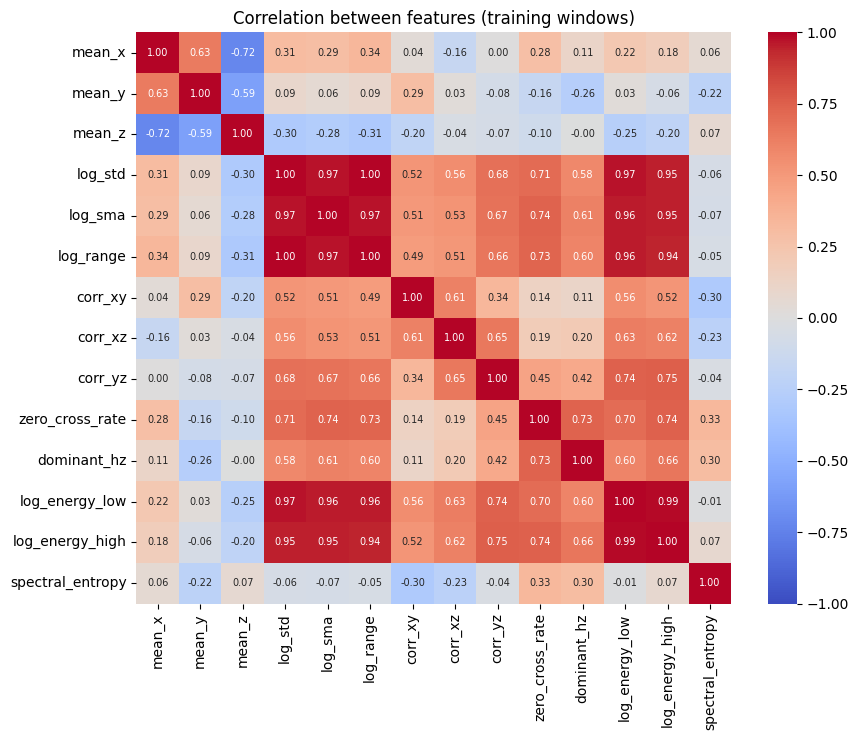

In [22]:
plt.figure(figsize=(9, 7.5))
sns.heatmap(train_features[FEATURE_NAMES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation between features (training windows)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_correlation.png", dpi=150)
plt.show()

### 17.1 What the F ratios and the heatmap show

**F ratios.** The best features are `log_energy_high` (11,700) and `log_energy_low` (6,500), then `log_std`, `log_sma` and `log_range` (about 2,000 to 2,300). `zero_cross_rate` and the three correlation features are in the middle (about 360 to 590). The weakest are `spectral_entropy` (69), `mean_z` (97) and `dominant_hz` (232). I need to be careful with these numbers. A big F ratio mostly means that jumping is very far from everything else. It does not say that standing and still are well separated, and they are the pair I am most worried about.

**The heatmap shows a lot of repetition.**
- `log_std`, `log_sma` and `log_range` are correlated at 0.97 to 1.00 with each other, and at 0.94 to 0.97 with the two energy features. The two energy features are correlated at 0.99 with each other. So these five features all say the same thing: how strong the movement is.
- `mean_x`, `mean_y` and `mean_z` are correlated with each other (-0.72 to 0.63), because they all come from how the phone is tilted.
- `zero_cross_rate` and `dominant_hz` are correlated at 0.73.
- The three correlation features are linked to the strength features (about 0.5 to 0.75) and a bit with each other (0.34 to 0.65). This is because only jumping has high correlation, and jumping is also the strongest movement.
- `spectral_entropy` is nearly independent from the rest (all values between -0.30 and 0.33), so it adds something different, even though it is weak.

**What I will do.** I keep all 14 features here, because each one has a reason and a clear job. But in the model part I will also try smaller sets, for example one strength feature instead of five. A Gaussian with a diagonal covariance counts every feature as separate evidence. Five features that repeat the same thing make the model too sure of itself about movement strength. I will compare the sets and report what I find.

# 18. Normalise the features

The features are on very different scales. `mean_z` is around 9, `corr_xy` is between -1 and 1, and `dominant_hz` is between 0.5 and 12. A Gaussian model with the raw values would care more about the features that have big numbers.

I use **z-score normalisation**: for every feature I subtract its average and divide by its standard deviation, so it has an average of 0 and a spread of 1. I chose it over min-max scaling because one strange window (like me reaching for the phone) would change the min or max and squash all the other values. The Gaussian emissions of the HMM also work in terms of averages and spreads, so z-scores fit them well.

The average and the spread are worked out **on the training windows only**. The test windows are then changed with the same numbers. If I used the test windows to work them out, information from the test would leak into the training.

In [23]:
feature_mean = train_features[FEATURE_NAMES].mean()
feature_std = train_features[FEATURE_NAMES].std(ddof=0).replace(0, 1.0)

z_features = ((feature_table[FEATURE_NAMES] - feature_mean) / feature_std).add_prefix("z_")
Z_NAMES = list(z_features.columns)
normalised = pd.concat([window_info, z_features], axis=1)
normalised.to_csv(OUT_ROOT / "features_normalised.csv", index=False)

check = pd.DataFrame({
    "train_mean": normalised.loc[normalised["split"] == "train", Z_NAMES].mean(),
    "train_std": normalised.loc[normalised["split"] == "train", Z_NAMES].std(ddof=0),
    "test_mean": normalised.loc[normalised["split"] == "test", Z_NAMES].mean(),
    "test_std": normalised.loc[normalised["split"] == "test", Z_NAMES].std(ddof=0),
}).round(2)
check

,train_mean,train_std,test_mean,test_std
z_mean_x,0.0,1.0,-0.72,0.68
z_mean_y,0.0,1.0,-0.13,0.74
z_mean_z,-0.0,1.0,0.58,0.55
z_log_std,0.0,1.0,-0.36,0.99
z_log_sma,-0.0,1.0,-0.36,0.97
z_log_range,-0.0,1.0,-0.38,1.03
z_corr_xy,0.0,1.0,0.04,0.81
z_corr_xz,0.0,1.0,-0.23,0.76
z_corr_yz,0.0,1.0,-0.58,0.69
z_zero_cross_rate,-0.0,1.0,-0.41,1.03


### 18.1 What the normalisation check shows

For the training windows every feature has an average of 0 and a spread of 1, as it should, because I worked the numbers out from them. The test windows are not exactly 0 and 1, and that is expected. There are two reasons.

1. **The test set has a different mix of activities.** It has many more still windows (164) than jumping windows (36), and the training set has the opposite balance. So the strength features have a test average of about -0.36 to -0.41 (more calm windows than in training). This is not a real change in the signal.
2. **The orientation features shifted too.** `z_mean_x` is -0.72, `z_mean_z` is +0.58 and `z_corr_yz` is -0.58, and the test spreads of the orientation features are smaller (0.55 to 0.74). Part of this is also the different mix: still lies flat, so more still windows pushes `mean_x` down and `mean_z` up. But part of it may be a real difference in how the phone was held in the test recordings. I can not separate the two from this table. Section 19 looks at standing windows alone, which shows the angle difference better.

So these averages are not a problem on their own. They are a reason to be careful when I read the test results, because if the model leans on the orientation, a standing window from the test set may look more like a still window.

# 19. A picture of all the features together

It is hard to look at 14 features at once. I use PCA to squash the 14 normalised features into 2 numbers for every window, keeping as much of the variation as possible. PCA is worked out from the training windows only. The circles are training windows and the crosses are test windows. This shows which activities overlap, and whether the test windows land in the same places as the training windows.

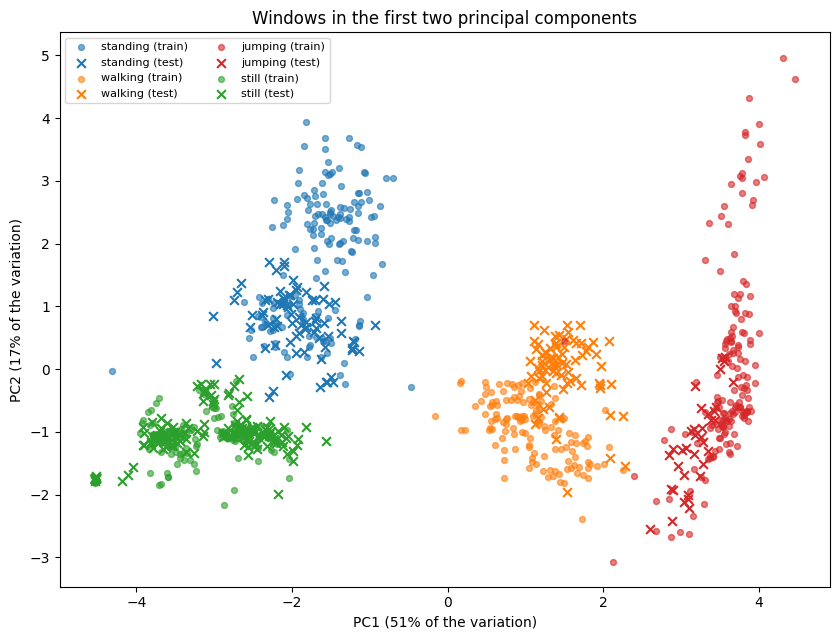

The first two components keep 68% of the variation.


In [24]:
train_z = normalised[normalised["split"] == "train"]
test_z = normalised[normalised["split"] == "test"]

centre = train_z[Z_NAMES].values.mean(axis=0)
_, singular, components = np.linalg.svd(train_z[Z_NAMES].values - centre, full_matrices=False)
explained = singular ** 2 / (singular ** 2).sum()

def project(frame):
    return (frame[Z_NAMES].values - centre) @ components[:2].T

fig, ax = plt.subplots(figsize=(8.5, 6.5))
for activity in ACTIVITIES:
    a = project(train_z[train_z["activity"] == activity])
    b = project(test_z[test_z["activity"] == activity])
    ax.scatter(a[:, 0], a[:, 1], s=18, alpha=0.6, color=palette[activity], label=f"{activity} (train)")
    ax.scatter(b[:, 0], b[:, 1], s=40, marker="x", color=palette[activity], label=f"{activity} (test)")
ax.set_xlabel(f"PC1 ({explained[0] * 100:.0f}% of the variation)")
ax.set_ylabel(f"PC2 ({explained[1] * 100:.0f}% of the variation)")
ax.set_title("Windows in the first two principal components")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_pca.png", dpi=150)
plt.show()
print(f"The first two components keep {explained[:2].sum() * 100:.0f}% of the variation.")

In [25]:
for activity in ACTIVITIES:
    for name, part in [("train", train_z), ("test", test_z)]:
        p = project(part[part["activity"] == activity])
        print(f"{activity:9s} {name:5s} PC1 mean {p[:, 0].mean():6.2f}   PC2 mean {p[:, 1].mean():6.2f}")
print("PC1 weights:", dict(zip(FEATURE_NAMES, components[0].round(2))))
print("PC2 weights:", dict(zip(FEATURE_NAMES, components[1].round(2))))

standing  train PC1 mean  -1.65   PC2 mean   1.79
standing  test  PC1 mean  -1.94   PC2 mean   0.75
walking   train PC1 mean   1.09   PC2 mean  -0.95
walking   test  PC1 mean   1.47   PC2 mean  -0.02
jumping   train PC1 mean   3.58   PC2 mean   0.01
jumping   test  PC1 mean   3.19   PC2 mean  -1.16
still     train PC1 mean  -3.24   PC2 mean  -1.16
still     test  PC1 mean  -3.14   PC2 mean  -1.08
PC1 weights: {'mean_x': np.float64(0.11), 'mean_y': np.float64(0.02), 'mean_z': np.float64(-0.11), 'log_std': np.float64(0.36), 'log_sma': np.float64(0.36), 'log_range': np.float64(0.36), 'corr_xy': np.float64(0.21), 'corr_xz': np.float64(0.23), 'corr_yz': np.float64(0.28), 'zero_cross_rate': np.float64(0.28), 'dominant_hz': np.float64(0.24), 'log_energy_low': np.float64(0.37), 'log_energy_high': np.float64(0.37), 'spectral_entropy': np.float64(-0.0)}
PC2 weights: {'mean_x': np.float64(0.48), 'mean_y': np.float64(0.58), 'mean_z': np.float64(-0.51), 'log_std': np.float64(0.03), 'log_sma': np.fl

### 19.1 What the PCA picture shows

**What the two axes are.** PC1 (51% of the variation) is the movement strength. The five strength features have the biggest weights (0.36 to 0.37). It sorts the activities from left to right: still and standing on the left, walking in the middle, jumping on the right. PC2 (17%) is mostly orientation. `mean_y` (0.58), `mean_z` (-0.51) and `mean_x` (0.48) have the biggest weights.

**What the picture shows.**
- The four groups are separate along PC1: still, standing, walking, jumping. Walking and jumping are far from each other, so these two should be easy to tell apart.
- **The test windows are not in exactly the same places as the training windows.** On PC1 they are close (the averages differ by 0.1 to 0.4), but on PC2 the difference is big for three activities. The PC2 average goes from 1.79 (train) to 0.75 (test) for standing, from -0.95 to -0.02 for walking, and from 0.01 to -1.16 for jumping. Still does not change (-1.16 and -1.08), which makes sense because it always lies flat. Since PC2 is the orientation, this means I held the phone at a different angle in the test recordings of standing, walking and jumping. This is a real difference in the data, and not only a result of the different mix of activities.
- **Standing is the one to watch.** The test standing windows moved down on PC2 towards still, and a few of them are near the top edge of the still group. They are still on the standing side along PC1, but I expect some standing windows to be confused with still.
- The jumping group is long and thin on PC2 (from about -2.7 to 5). The phone angle changed a lot between jumping windows, I think because it moves in my hand while I jump.

**What this means for the model.** The activities are separated mainly by movement strength (PC1), and that does not depend on how I hold the phone. The orientation features (PC2) changed between the training and test recordings, so a model that depends on them can be thrown off. This is a good reason to compare feature sets with and without the orientation features in the model part.

The two components keep 68% of the variation, so this picture is a simplified view. The real separation in 14 dimensions can be better or worse than it looks here.

# 20. What comes next

The features are ready. The table `normalised` has one row for every window with its split, activity, recording and time, and it is saved as `features_normalised.csv`. The model part is in a separate notebook that loads this file. It will cover:

- how to turn the windows into observation sequences for the HMM
- the HMM parts and the model written from scratch in numpy, with Viterbi and Baum-Welch
- training, the transition matrix heatmap and the decoded sequence plots
- testing on the unseen recordings, with sensitivity, specificity, accuracy and a confusion matrix
- my own reflection on what was easy, what was hard, and what I would improve

# 14. What comes next

The data is ready. The next parts of this notebook will cover:

- features from each window (time domain and frequency domain) and how they are normalised
- the HMM parts and the model written from scratch in numpy, with Viterbi and Baum-Welch
- training, the transition matrix heatmap and the decoded sequence plots
- testing on the unseen recordings, with sensitivity, specificity, accuracy and a confusion matrix
- my own reflection on what was easy, what was hard, and what I would improve